# House Price Prediction

Predicting house sale prices from listing details (floor area, bedrooms, toilets, stories, renovation status and city) with scikit-learn regression models.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy.stats import randint
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

## Loading the data

In [2]:
df = pd.read_csv("data/housing_price_data.csv")

## 1. Exploratory Data Analysis

Steps:
1. Understand the data
2. Clean the data and handle missing values
3. Visualise the data

### 1.1 Understand the data

In [3]:
print("Shape:", df.shape)
df.info()
df.head()

Shape: (545, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   House ID           545 non-null    int64  
 1   City               545 non-null    object 
 2   House Area (sqm)   545 non-null    float64
 3   No. of Bedrooms    545 non-null    int64  
 4   No. of Toilets     545 non-null    int64  
 5   Stories            545 non-null    int64  
 6   Renovation Status  545 non-null    object 
 7   Price ($)          545 non-null    int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 34.2+ KB


,House ID,City,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Renovation Status,Price ($)
0,0,Chicago,742.0,4,2,3,furnished,1330000
1,1,Denver,896.0,4,4,4,furnished,1225000
2,2,Chicago,996.0,3,2,2,semi-furnished,1225000
3,3,Seattle,750.0,4,2,2,furnished,1221500
4,4,New York,742.0,4,1,2,furnished,1141000


In [4]:
# Check for missing values (there are none)
df.isna().sum()

House ID             0
City                 0
House Area (sqm)     0
No. of Bedrooms      0
No. of Toilets       0
Stories              0
Renovation Status    0
Price ($)            0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

### 1.2 Clean the data and handle missing values

In [6]:
# Drop duplicate rows
df = df.drop_duplicates()

In [7]:
# Drop rows with missing values
df.dropna(inplace=True)

In [8]:
# Check the data after cleaning
print("After cleaning:")
print("Shape:", df.shape)
df.isna().sum().sort_values()

After cleaning:
Shape: (545, 8)


House ID             0
City                 0
House Area (sqm)     0
No. of Bedrooms      0
No. of Toilets       0
Stories              0
Renovation Status    0
Price ($)            0
dtype: int64

In [9]:
# House ID is just an identifier, so it isn't a useful feature
df = df.drop(columns=['House ID'])

In [10]:
df.describe()

,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Price ($)
count,545.000000,545.000000,545.000000,545.000000,5.450000e+02
mean,515.054128,2.965138,1.286239,1.805505,4.766729e+05
std,217.014102,0.738064,0.502470,0.867492,1.870440e+05
min,165.000000,1.000000,1.000000,1.000000,1.750000e+05
25%,360.000000,2.000000,1.000000,1.000000,3.430000e+05
50%,460.000000,3.000000,1.000000,2.000000,4.340000e+05
75%,636.000000,3.000000,2.000000,2.000000,5.740000e+05
max,1620.000000,6.000000,4.000000,4.000000,1.330000e+06


### 1.3 Visualise the data

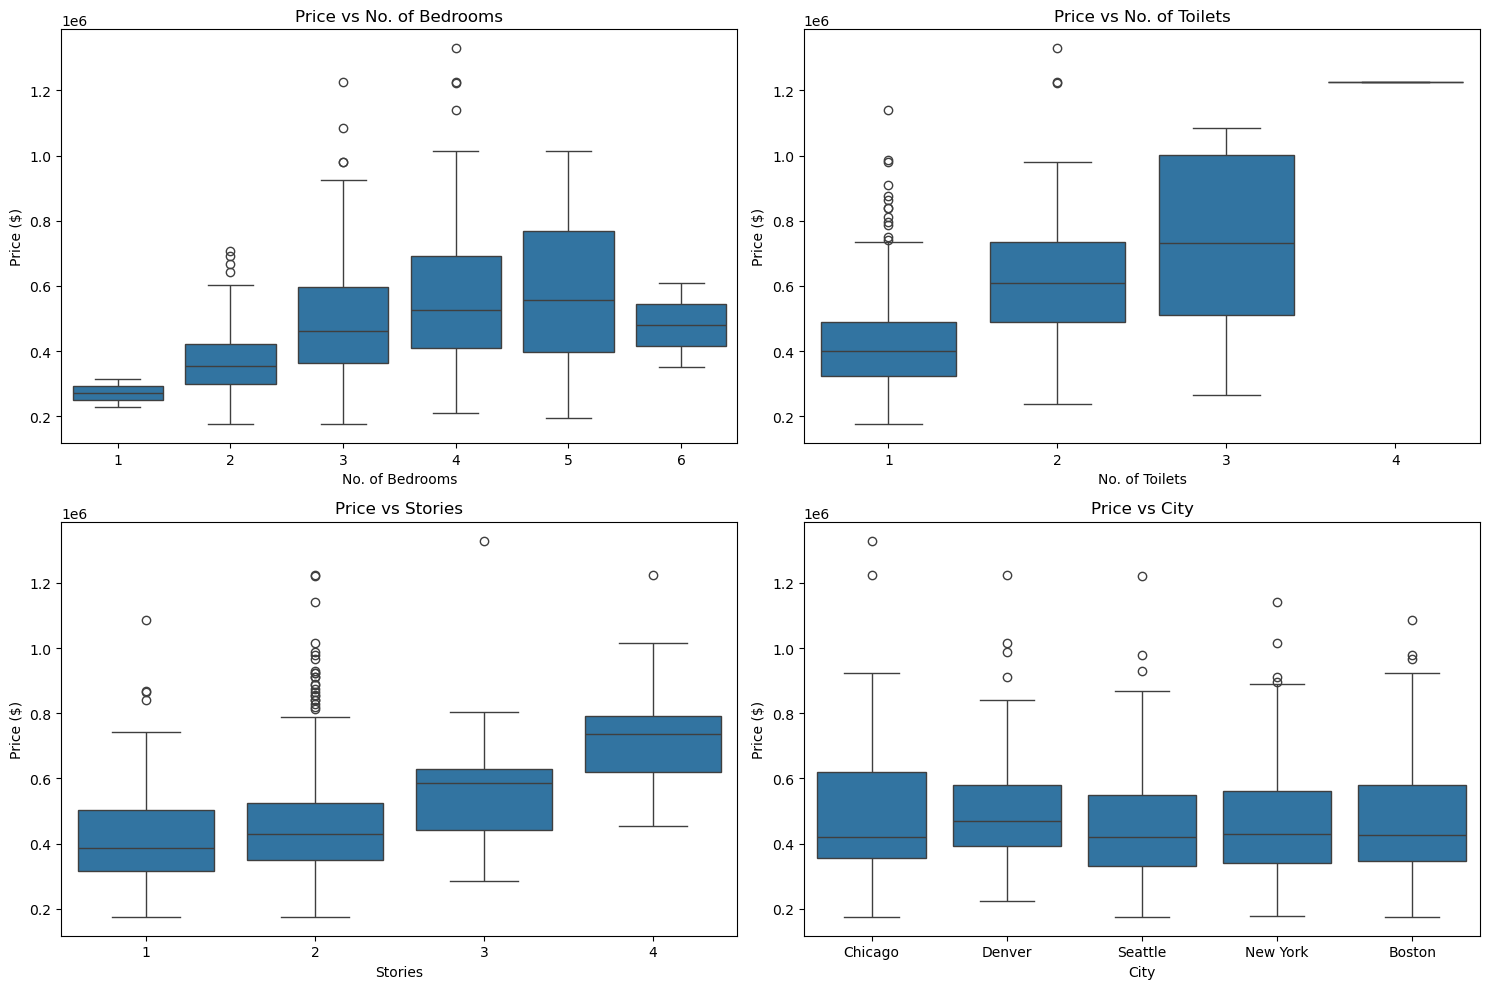

In [11]:
# Price against each discrete feature
# Note: only one house has 4 toilets
num_cols = ['No. of Bedrooms', 'No. of Toilets', 'Stories', 'City']

plt.figure(figsize=(15,10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2,2,i)
    sns.boxplot(data=df, x=col, y='Price ($)')
    plt.title(f'Price vs {col}', fontsize=12)
plt.tight_layout()
plt.show()

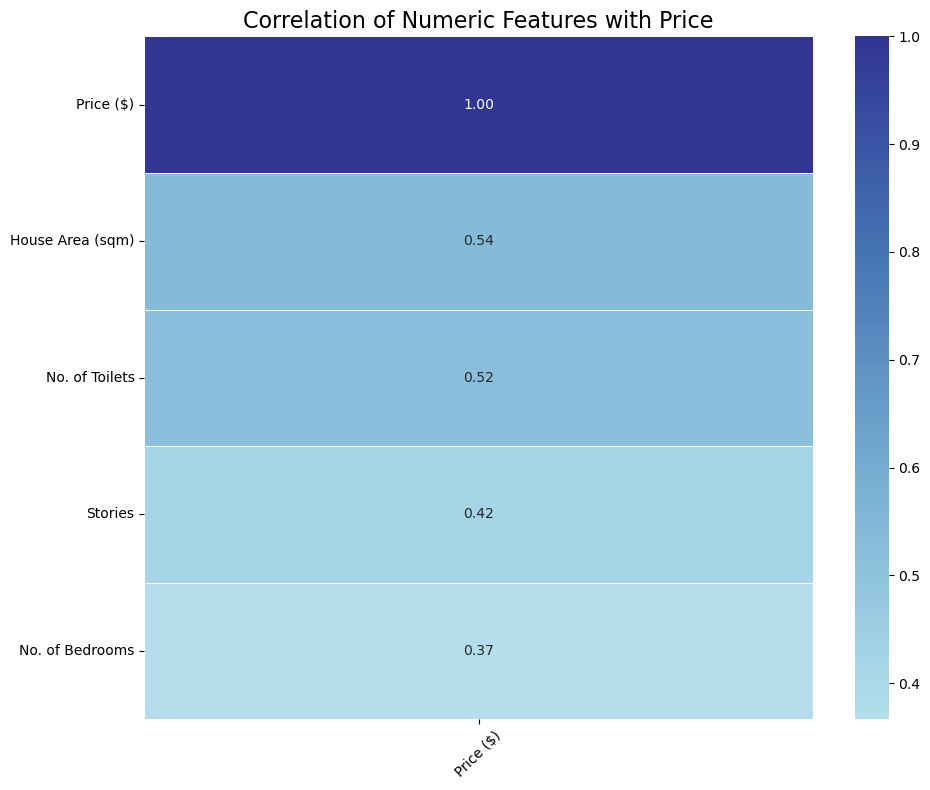

In [12]:
numeric_df = df.select_dtypes(include='number')
price_corr = numeric_df.corr()[['Price ($)']].sort_values(by='Price ($)', ascending=False)

plt.figure(figsize=(10,8))
sns.heatmap(price_corr, annot=True, fmt=".2f", cmap='RdYlBu', center=0, linewidths=0.5)
plt.title('Correlation of Numeric Features with Price', fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

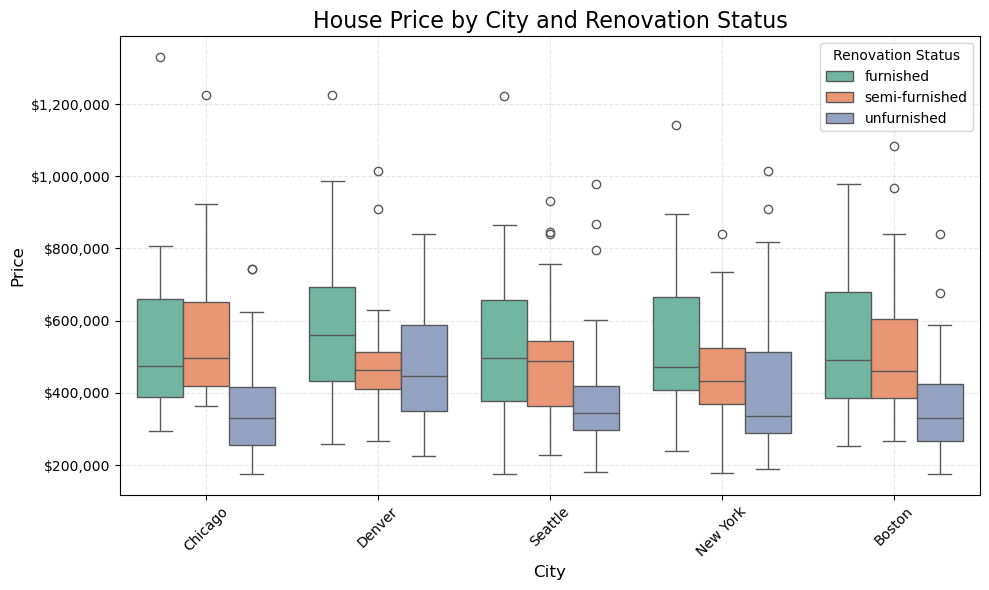

In [13]:
# Format the y-axis as dollars with commas
def dollar_formatter(x, pos):
    return f"${int(x):,}"

plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x='City',
    y='Price ($)',
    hue='Renovation Status',
    palette='Set2'
)

plt.title("House Price by City and Renovation Status", fontsize=16)
plt.xlabel("City", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.xticks(rotation=45)
plt.grid(alpha=0.3, linestyle='--')
plt.gca().yaxis.set_major_formatter(FuncFormatter(dollar_formatter))

plt.legend(title='Renovation Status', loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

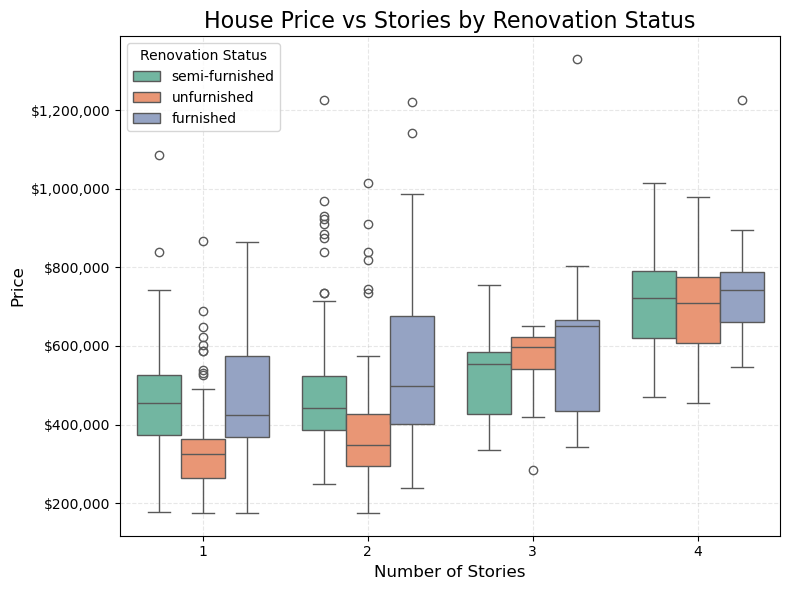

In [14]:
plt.figure(figsize=(8,6))
sns.boxplot(
    data=df,
    x='Stories',
    y='Price ($)',
    hue='Renovation Status',
    palette='Set2'
)

plt.title("House Price vs Stories by Renovation Status", fontsize=16)
plt.xlabel("Number of Stories", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.grid(alpha=0.3, linestyle='--')
plt.gca().yaxis.set_major_formatter(FuncFormatter(dollar_formatter))

plt.legend(title='Renovation Status', loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

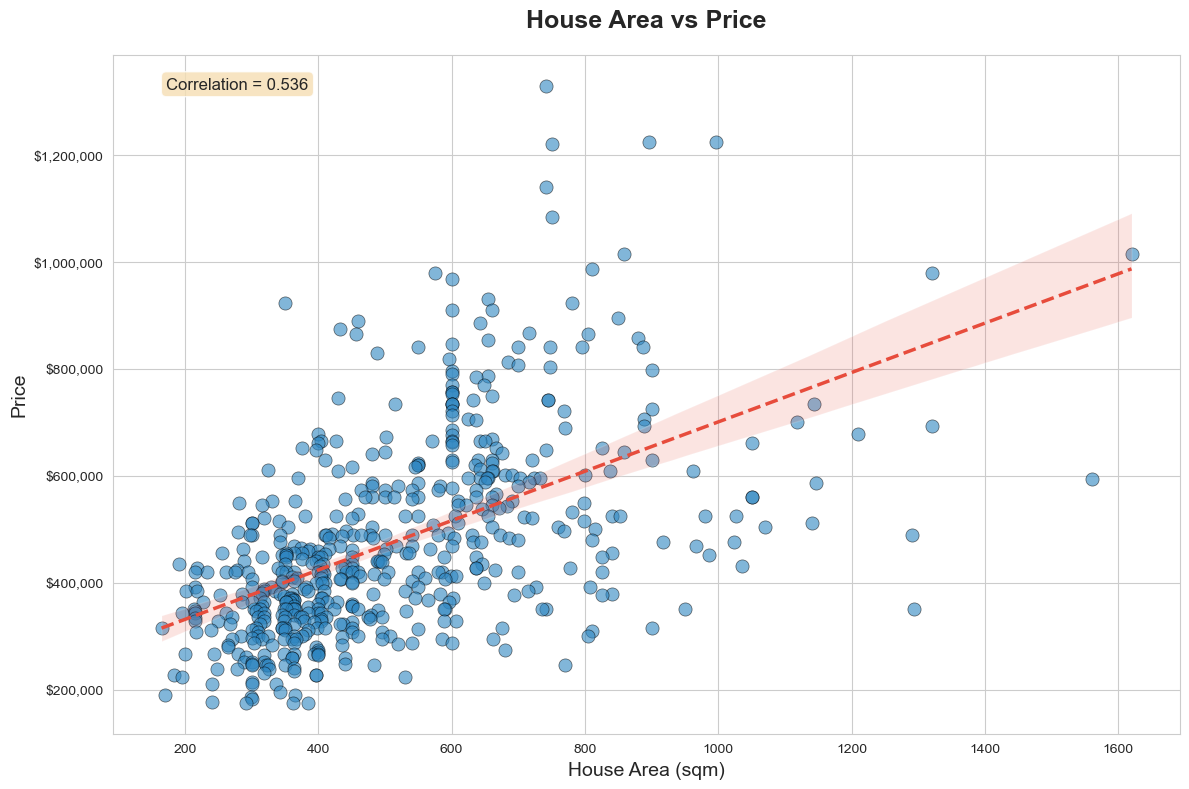

In [15]:
sns.set_style("whitegrid")
plt.figure(figsize=(12, 8))

# Area against price, with a fitted regression line
sns.scatterplot(
    data=df,
    x='House Area (sqm)',
    y='Price ($)',
    alpha=0.6,
    s=90,
    color='#2E86C1',
    edgecolor='black',
    linewidth=0.5
)
sns.regplot(
    data=df,
    x='House Area (sqm)',
    y='Price ($)',
    scatter=False,
    color='#E74C3C',
    line_kws={"linewidth": 2.5, "linestyle": "--"}
)

plt.title("House Area vs Price", fontsize=18, fontweight='bold', pad=20)
plt.xlabel('House Area (sqm)', fontsize=14)
plt.ylabel('Price', fontsize=14)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"${x:,.0f}"))

correlation = df['House Area (sqm)'].corr(df['Price ($)'])
plt.text(0.05, 0.95, f"Correlation = {correlation:.3f}",
         transform=plt.gca().transAxes, fontsize=12,
         bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

plt.tight_layout()
plt.show()

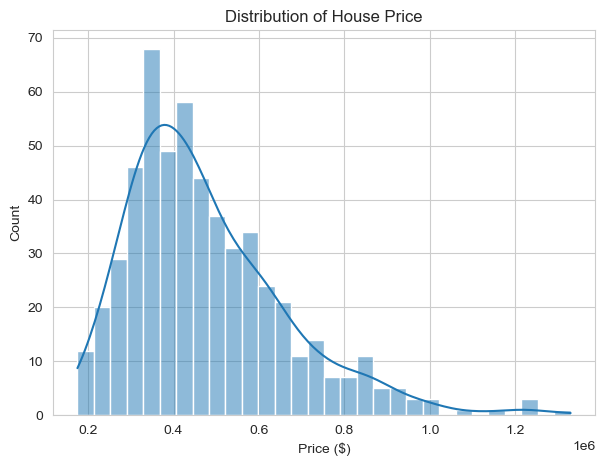

In [16]:
plt.figure(figsize=(7,5))
sns.histplot(df['Price ($)'], bins=30, kde=True)
plt.title("Distribution of House Price")
plt.show()


## 2. Modelling

Steps:
1. Cross-validate baseline models
2. Split, engineer features and preprocess without leaking test data
3. Retrain with the engineered features
4. Tune hyperparameters (training set only)
5. Final evaluation on the held-out test set

### 2.1 Baseline models: 5-fold cross-validation

In [17]:
# Model log(1 + price), because prices are right-skewed
df['Log_Price'] = np.log1p(df['Price ($)'])

# One-hot encode the categorical features
df_encoded = pd.get_dummies(df, columns=['City', 'Renovation Status'], drop_first=True)

X = df_encoded.drop(['Log_Price', 'Price ($)'], axis=1)
y = df_encoded['Log_Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Lasso Regression': Lasso(alpha=0.01, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("5-fold cross-validation R² per model:\n")
for key, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
    q25, q50, q75 = np.quantile(scores, [0.25, 0.5, 0.75])
    print(f"{key:25} → mean R²: {scores.mean():.4f}, std: {scores.std():.4f}, "
          f"25%: {q25:.4f}, 50%: {q50:.4f}, 75%: {q75:.4f}")

5-fold cross-validation R² per model:

Linear Regression         → mean R²: 0.5257, std: 0.0523, 25%: 0.4805, 50%: 0.5013, 75%: 0.5777
Ridge Regression          → mean R²: 0.5265, std: 0.0518, 25%: 0.4827, 50%: 0.5014, 75%: 0.5789
Lasso Regression          → mean R²: 0.5333, std: 0.0473, 25%: 0.4940, 50%: 0.5126, 75%: 0.5860


Random Forest             → mean R²: 0.5084, std: 0.0604, 25%: 0.4671, 50%: 0.5031, 75%: 0.5606


### 2.2 Split, feature engineering and preprocessing

In [18]:
# Split first, so nothing about the test set influences preprocessing
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Feature engineering, applied to train and test separately.
# Every feature must be computable for a new house before its price is known.
def engineer_features(d):
    d = d.copy()
    d['Total_Rooms']    = d['No. of Bedrooms'] + d['No. of Toilets']
    d['Area_per_Story'] = d['House Area (sqm)'] / d['Stories']
    d['Log_Price']      = np.log1p(d['Price ($)'])  # target
    return d

train_df = engineer_features(train_df)
test_df  = engineer_features(test_df)

# One-hot encode, then give the test set exactly the training set's columns
categorical_cols = ['City', 'Renovation Status']
train_encoded = pd.get_dummies(train_df, columns=categorical_cols, drop_first=True)
test_encoded  = pd.get_dummies(test_df, columns=categorical_cols, drop_first=True)
test_encoded  = test_encoded.reindex(columns=train_encoded.columns, fill_value=0)

X_train_new = train_encoded.drop(['Price ($)', 'Log_Price'], axis=1)
y_train_new = train_encoded['Log_Price']
X_test_new  = test_encoded.drop(['Price ($)', 'Log_Price'], axis=1)
y_test_new  = test_encoded['Log_Price']

# Standardise numeric features: fit the scaler on the training set only
numeric_cols = ['House Area (sqm)', 'No. of Bedrooms', 'No. of Toilets', 'Stories',
                'Total_Rooms', 'Area_per_Story']

scaler = StandardScaler()
X_train_scaled = X_train_new.copy()
X_test_scaled  = X_test_new.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
X_test_scaled[numeric_cols]  = scaler.transform(X_test_scaled[numeric_cols])

### 2.3 Retrain with engineered features

In [19]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=42),
    "Lasso": Lasso(alpha=0.01, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("5-fold cross-validation R² (after feature engineering):\n")
for name, model in models.items():
    # Linear models use scaled features; Random Forest doesn't need scaling
    if name != "Random Forest":
        scores = cross_val_score(model, X_train_scaled, y_train_new, cv=kf, scoring='r2')
    else:
        scores = cross_val_score(model, X_train_new, y_train_new, cv=kf, scoring='r2')

    q25, q50, q75 = np.quantile(scores, [0.25, 0.5, 0.75])
    print(f"{name:20} → Mean R²: {scores.mean():.4f}, Std: {scores.std():.4f}, "
          f"25%: {q25:.4f}, 50%: {q50:.4f}, 75%: {q75:.4f}")

5-fold cross-validation R² (after feature engineering):

Linear Regression    → Mean R²: 0.5289, Std: 0.0499, 25%: 0.4830, 50%: 0.5026, 75%: 0.5821
Ridge                → Mean R²: 0.5296, Std: 0.0495, 25%: 0.4838, 50%: 0.5032, 75%: 0.5829
Lasso                → Mean R²: 0.5350, Std: 0.0472, 25%: 0.5033, 50%: 0.5067, 75%: 0.5914


Random Forest        → Mean R²: 0.5050, Std: 0.0620, 25%: 0.4912, 50%: 0.4961, 75%: 0.5609


### 2.4 Hyperparameter tuning (training set only)

In [20]:
rf = RandomForestRegressor(random_state=42)

param_dist = {
    "n_estimators": randint(200, 1000),
    "max_depth": randint(5, 25),            # limit depth to reduce overfitting
    "min_samples_split": randint(5, 20),
    "min_samples_leaf": randint(2, 10),
}

rf_random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=50,
    scoring='r2',
    cv=5,
    n_jobs=-1,
    verbose=0,
    random_state=42
)
rf_random_search.fit(X_train_new, y_train_new)

print("Best hyperparameters:")
print(rf_random_search.best_params_)

mean_cv_r2 = rf_random_search.cv_results_['mean_test_score'][rf_random_search.best_index_]
print(f"Mean CV R² (best model): {mean_cv_r2:.4f}")

Best hyperparameters:
{'max_depth': 17, 'min_samples_leaf': 2, 'min_samples_split': 17, 'n_estimators': 214}
Mean CV R² (best model): 0.5587


### 2.5 Final evaluation on the held-out test set

In [21]:
best_rf = rf_random_search.best_estimator_

# Predict log price, then convert back to dollars (undo log1p)
y_pred_test = np.expm1(best_rf.predict(X_test_new))
y_test_true = np.expm1(y_test_new)

final_r2 = r2_score(y_test_true, y_pred_test)
final_rmse = np.sqrt(mean_squared_error(y_test_true, y_pred_test))

print("Final performance on the test set (original price scale):")
print(f"R²:   {final_r2:.5f}")
print(f"RMSE: ${final_rmse:,.2f}")

Final performance on the test set (original price scale):
R²:   0.49092
RMSE: $160,412.11
